# Credit Card Fraud Detection Using Machine Learning


# Introduction

Credit card fraud is the unauthorized use of credit card information to perform financial transactions. Detecting fraudulent transactions is essential for protecting customers and reducing financial losses.

Machine learning techniques can analyze transaction patterns and classify transactions as legitimate or fraudulent. However, fraud detection is challenging because fraudulent transactions are much less frequent than legitimate transactions.

This project uses the Credit Card Fraud Detection dataset from Kaggle to explore transaction patterns, handle class imbalance, and build machine learning models for fraud classification. Logistic Regression and Random Forest are used to compare predictive performance.

The models are evaluated using Precision, Recall, F1-score, ROC-AUC, and confusion matrices rather than relying only on accuracy.

## Objectives

- Analyze the distribution of fraudulent and legitimate transactions.
- Perform exploratory data analysis on transaction amounts and elapsed time.
- Handle class imbalance using balanced class weights.
- Train and compare two machine learning models.
- Evaluate model performance using appropriate classification metrics.
- Identify important features and discuss scalability.

## Dataset Description

The dataset is obtained from Kaggle and contains 284,807 transactions, of which 492 are fraudulent. It includes 28 anonymized features obtained through Principal Component Analysis (PCA), along with `Time`, `Amount`, and `Class`.

The target column `Class` contains two values:
- `0` – Legitimate transaction
- `1` – Fraudulent transaction

## Tools and Technologies

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and Jupyter Notebook.


## 1. Import Required Libraries

Import the Python libraries required for data loading, numerical operations, visualization, data preprocessing, model training, and evaluation.



In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

sns.set_theme(style="whitegrid")



## 2. Load the Dataset

Load the credit card transaction dataset into a Pandas DataFrame. Display its dimensions and the first few rows to understand its structure and the available features.


In [2]:

df = pd.read_csv("creditcard.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



## 3. Initial Data Inspection

Examine the dataset's data types, missing values, duplicate records, and statistical summaries. This step helps identify data quality issues before performing further analysis.


In [3]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


### 4. Distribution of Legitimate and Fraudulent Transactions

This analysis examines the distribution of legitimate and fraudulent transactions in the dataset. The `Class` column represents the transaction category, where **0 indicates a legitimate transaction and 1 indicates a fraudulent transaction**.

The `value_counts()` function calculates the number of transactions in each class, while `value_counts(normalize=True)` calculates their proportions. Multiplying the proportions by 100 converts them into percentages.

A count plot is used to visualise the number of transactions in each class. This helps identify whether the dataset is balanced or imbalanced. Fraud detection datasets often contain significantly fewer fraudulent transactions than legitimate transactions, a condition known as class imbalance.

Understanding the class distribution is important because a highly imbalanced dataset can make accuracy alone misleading when evaluating a fraud detection model.


Transaction counts:
Class
Legitimate    284315
Fraud            492
Name: count, dtype: int64

Transaction percentages:
Class
Legitimate    99.8273
Fraud          0.1727
Name: proportion, dtype: float64


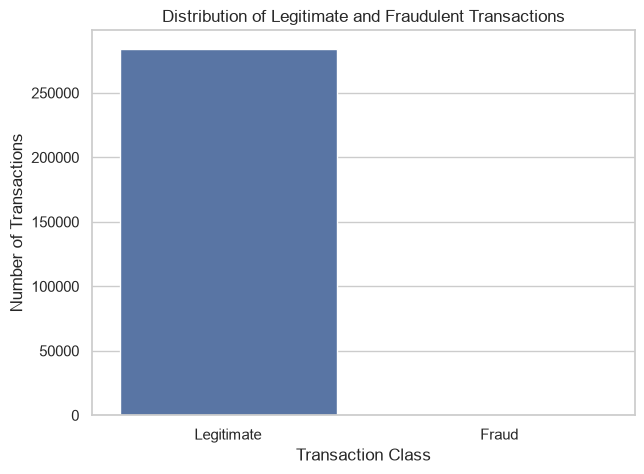

In [4]:

class_counts = df["Class"].value_counts().sort_index()
class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

print("Transaction counts:")
print(class_counts.rename(index={0: "Legitimate", 1: "Fraud"}))

print("\nTransaction percentages:")
print(class_percentages.rename(index={0: "Legitimate", 1: "Fraud"}).round(4))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Class")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.show()


### Observation

The count plot compares the number of legitimate and fraudulent transactions in the dataset. The transaction counts and percentages indicate the proportion of each class. If fraudulent transactions represent a much smaller percentage than legitimate transactions, the dataset is highly imbalanced. Therefore, suitable evaluation metrics such as precision, recall, and F1-score should be considered when developing a fraud detection model.


### 5.Transaction Amount Analysis Using a Box Plot

A box plot is used to compare the distribution of transaction amounts between legitimate and fraudulent transactions. In this analysis, the `Class` column distinguishes legitimate transactions (0) from fraudulent transactions (1), while the `Amount` column represents the monetary value of each transaction.

The box plot displays the median, lower and upper quartiles, and potential outliers for each class. It helps identify differences in transaction amounts, data variability, and unusually large or small transactions.

Comparing both classes can help determine whether fraudulent transactions exhibit different spending patterns. However, transaction amount alone cannot reliably determine whether a transaction is fraudulent.


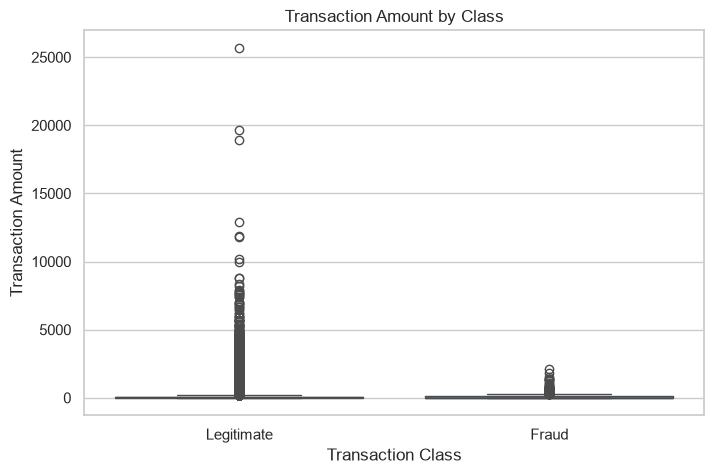

In [5]:

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Class", y="Amount")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title("Transaction Amount by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.show()


### Observation

The box plot compares transaction amounts for legitimate and fraudulent transactions. The median lines indicate the central transaction amount, while the box sizes represent the spread of the middle 50% of observations. Points beyond the whiskers indicate potential outliers.

Differences in the medians, spreads, or outliers may indicate variations in transaction patterns between the two classes. These patterns can help identify features worth investigating further during fraud detection.


### 6. Time-Based Analysis of Fraudulent Transactions

Time-based analysis helps identify how fraudulent transactions are distributed across different time intervals. In this analysis, the `Time` column represents the elapsed time in seconds from the beginning of the dataset's observation period.

The time values are divided by 3,600 to convert seconds into hourly intervals. The data is then filtered to include only fraudulent transactions, and the number of fraud cases within each interval is calculated using grouping and aggregation.

A line chart is used to visualise the number of fraudulent transactions across these intervals. This analysis can help identify periods with higher fraud activity and understand potential temporal patterns in transaction behaviour.


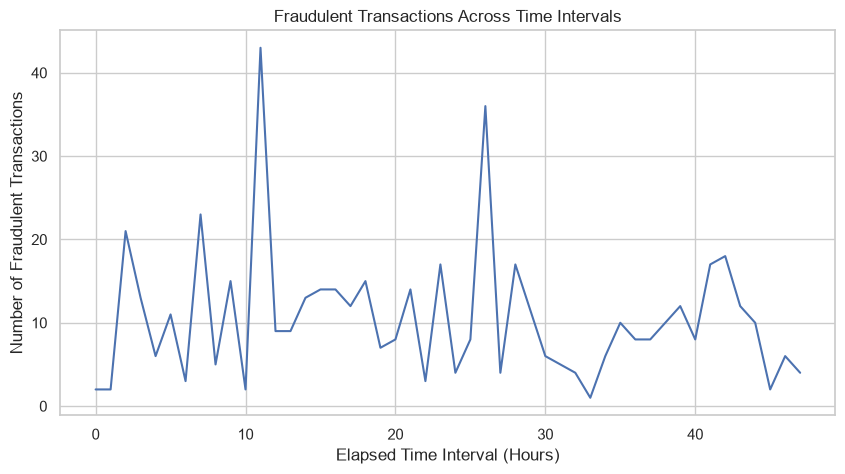

In [6]:

df["Time Interval"] = (df["Time"] // 3600).astype(int)

fraud_by_interval = df[df["Class"] == 1].groupby("Time Interval").size()

plt.figure(figsize=(10, 5))
fraud_by_interval.plot(kind="line")
plt.title("Fraudulent Transactions Across Time Intervals")
plt.xlabel("Elapsed Time Interval (Hours)")
plt.ylabel("Number of Fraudulent Transactions")
plt.show()


### Observation

The line chart shows the number of fraudulent transactions across elapsed hourly intervals. Peaks indicate intervals with relatively higher numbers of fraudulent transactions, while lower points indicate fewer cases.

These variations may reveal temporal patterns in fraudulent activity. However, the results represent the distribution of fraud cases in the observed dataset and do not necessarily indicate the actual time of day or prove that a particular interval causes fraud.


### 7. Data Splitting and Feature Standardisation

Before building a fraud detection model, the dataset is divided into input features and the target variable. The `Class` column is selected as the target, where 0 represents legitimate transactions and 1 represents fraudulent transactions. The `Time Interval` column is excluded because it was created specifically for visualisation.

The `train_test_split()` function divides the dataset into training and testing sets. In this analysis, 80% of the data is used for training and 20% for testing. The `stratify=y` parameter preserves approximately the same proportion of legitimate and fraudulent transactions in both sets, which is important when the dataset is imbalanced.

`StandardScaler` is used to standardise the `Time` and `Amount` features so that they have a mean close to zero and a standard deviation close to one. The scaler is fitted only on the training data and then applied to both datasets to prevent data leakage.

Finally, the dimensions and class distributions of the training and testing sets are displayed to verify the split and check the representation of both transaction classes.


In [7]:

X = df.drop(columns=["Class", "Time Interval"], errors="ignore")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

X_test[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]]
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training set: (227845, 30)
Testing set: (56962, 30)

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing class distribution:
Class
0    56864
1       98
Name: count, dtype: int64


### Observation

The dataset is divided into training and testing sets using an 80:20 ratio. Stratified splitting helps maintain the original proportion of legitimate and fraudulent transactions in both sets. The `Time` and `Amount` features are standardised using statistics calculated from the training data.

The printed dimensions confirm the number of records and features available in each set, while the class distributions show how fraudulent and legitimate transactions are represented for model training and evaluation.


### 8.Model Training Using Logistic Regression and Random Forest

Machine learning models can be used to classify transactions as legitimate or fraudulent based on their input features. In this project, Logistic Regression and Random Forest are trained to compare their performance in fraud detection.

**Logistic Regression** is a supervised classification algorithm that estimates the probability of a transaction belonging to a particular class. It is a simple and interpretable model that can serve as a baseline for binary classification.

**Random Forest** is an ensemble learning algorithm that combines predictions from multiple decision trees. It can capture complex relationships between transaction features and is useful for classification tasks involving nonlinear patterns.

The `class_weight="balanced"` parameter assigns greater importance to underrepresented classes according to their frequencies in the training data. This helps address class imbalance during model training. The `max_iter=1000` parameter allows Logistic Regression more iterations to converge, while `n_estimators=100` specifies 100 decision trees for Random Forest.

Both models are fitted using the training dataset so that their predictions can later be evaluated on unseen testing data.


In [9]:

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both models trained successfully.")


Both models trained successfully.


### 9. Model Evaluation and Performance Comparison

After training the Logistic Regression and Random Forest models, their performance is evaluated using the testing dataset. Model evaluation helps determine how effectively each algorithm distinguishes fraudulent transactions from legitimate transactions.

The following metrics are calculated:

- **Precision:** Measures the proportion of transactions predicted as fraudulent that are actually fraudulent. High precision indicates fewer false fraud alerts.
- **Recall:** Measures the proportion of actual fraudulent transactions correctly identified by the model. High recall is important for detecting more fraud cases.
- **F1-score:** Represents the harmonic mean of precision and recall, balancing both metrics.
- **ROC-AUC:** Measures how effectively a model distinguishes between the two classes across different classification thresholds. A higher value generally indicates better discrimination.

The `predict()` function generates predicted transaction classes, while `predict_proba()` provides predicted probabilities. The probability of the fraudulent class is used to calculate ROC-AUC.

The evaluation results are stored in a Pandas DataFrame and displayed in tabular form, allowing the performance of both models to be compared using the same testing data.


In [10]:

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))


,Model,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.0610,0.9184,0.1144,0.9722
1,Random Forest,0.9605,0.7449,0.8391,0.9529


### 10. ROC Curve Comparison

The Receiver Operating Characteristic (ROC) curve is used to evaluate and compare the classification performance of machine learning models. In this project, the ROC curves of Logistic Regression and Random Forest are plotted to assess their ability to distinguish fraudulent transactions from legitimate transactions.

The ROC curve plots the **True Positive Rate (TPR)** against the **False Positive Rate (FPR)** at different classification thresholds.

- **True Positive Rate (TPR):** The proportion of actual fraudulent transactions correctly identified as fraud.
- **False Positive Rate (FPR):** The proportion of legitimate transactions incorrectly classified as fraud.
- **Area Under the Curve (AUC):** Summarises the model's ability to distinguish between the two classes. A value closer to 1 indicates stronger discrimination, while a value near 0.5 indicates performance similar to random ranking.

The dashed diagonal line represents a random classifier. A model whose ROC curve stays above this line generally performs better than random classification. Comparing both curves helps determine which model offers better discrimination across different thresholds.


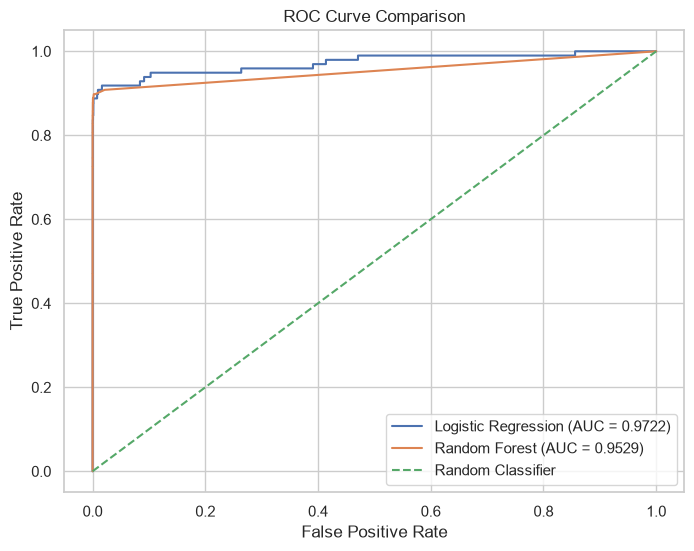

In [11]:

plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()


### Observation

The ROC curve compares the performance of Logistic Regression and Random Forest across different classification thresholds. The curves show the trade-off between detecting fraudulent transactions and incorrectly flagging legitimate transactions.

The AUC values in the legend help compare the models. The model with the higher AUC generally has better ability to distinguish fraudulent transactions from legitimate ones. The final conclusion should be based on the actual curves and AUC values observed in the graph.


### 11.Confusion Matrix Comparison

A confusion matrix is used to evaluate the performance of a classification model by comparing actual transaction classes with predicted classes. It helps identify correctly classified transactions and classification errors.

The confusion matrix contains four values:

**True Negative (TN):** Legitimate transactions correctly predicted as legitimate.

**True Positive (TP):** Fraudulent transactions correctly predicted as fraud.

**False Positive (FP):** Legitimate transactions incorrectly predicted as fraud.

**False Negative (FN):** Fraudulent transactions incorrectly predicted as legitimate.

In this code, confusion matrices are generated for both Logistic Regression and Random Forest models. The heatmap displays the values using colour intensity, making it easier to compare their performance.

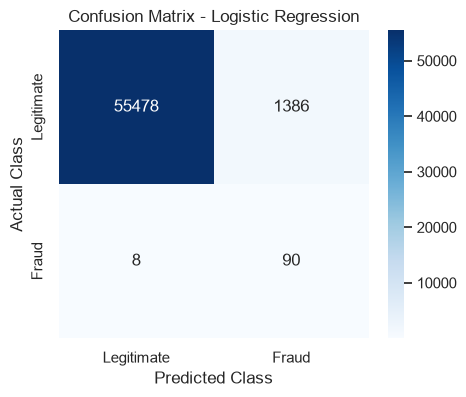

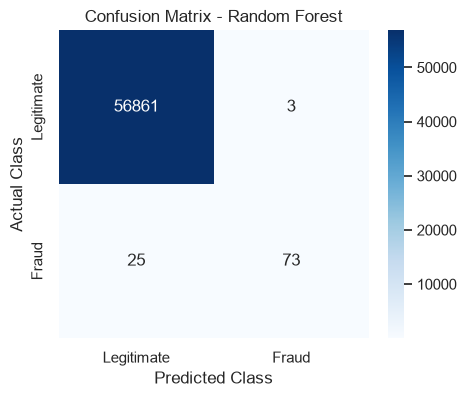

In [12]:

for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"]
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.show()


### Observation

The confusion matrices show how accurately Logistic Regression and Random Forest classify legitimate and fraudulent transactions. A higher number of true positives indicates that more fraudulent transactions are detected, while a lower number of false negatives means fewer fraudulent transactions go undetected. False positives represent legitimate transactions incorrectly flagged as fraud.

By comparing both matrices, the model with fewer classification errors and better fraud detection can be identified. The final conclusion should be based on the actual values displayed in the heatmaps

### Feature Importance Analysis Using Random Forest

Feature importance identifies the input variables that contribute most to the predictions made by a machine learning model. In fraud detection, it helps determine which transaction features are most useful for distinguishing legitimate transactions from fraudulent ones.

The Random Forest model calculates feature importance based on how much each feature contributes to reducing impurity across the decision trees. Higher importance values indicate that a feature has a greater influence on the model's predictions.

In this code:

feature_importances_ retrieves the importance scores calculated by the trained Random Forest model.

pd.Series() associates each importance score with its corresponding feature name.

sort_values(ascending=False) arranges the features from highest to lowest importance.

head(10) selects the ten most important features.

The horizontal bar chart visualizes the top ten features, while the table displays their importance scores.

Feature importance helps understand the model's behaviour and identify influential transaction characteristics. However, importance does not establish a causal relationship or indicate whether a feature increases or decreases the likelihood of fraud.

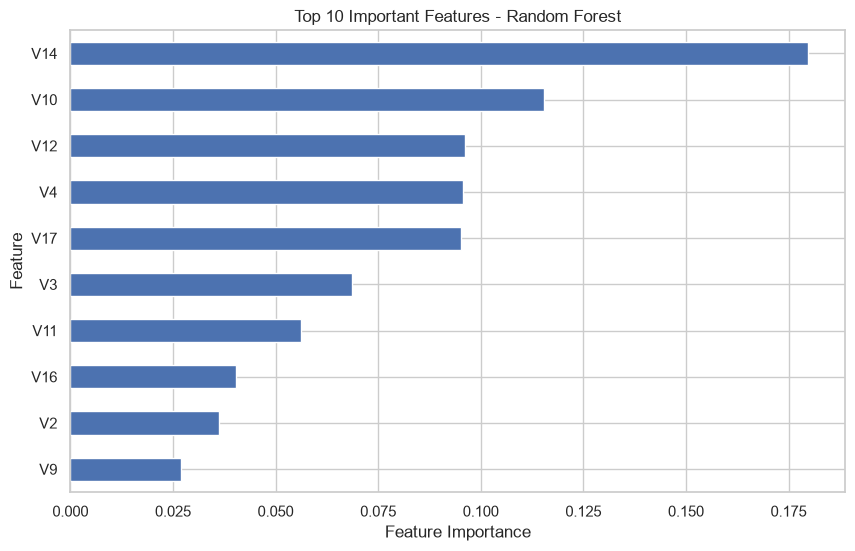

,Importance
V14,0.179857
V10,0.115442
V12,0.096206
V4,0.095646
V17,0.095113
V3,0.068669
V11,0.056112
V16,0.040303
V2,0.036265
V9,0.026888


In [13]:

importance = pd.Series(
    random_forest_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importance.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

display(importance.head(10).to_frame("Importance"))



### Observation

The bar chart and table display the ten features that contribute most to the Random Forest model's predictions, ranked by their importance scores. Features with higher scores have a greater influence on the model's decision-making process.

These results help identify the most influential variables for fraud detection. The specific top features and their importance values should be interpreted from the generated chart and table.

## Key Findings and Insights

- **Class Imbalance:** The dataset contains significantly more legitimate transactions than fraudulent transactions, making fraud detection a challenging classification problem.
- **Transaction Analysis:** Transaction amounts and time intervals were analyzed to understand the distribution and patterns of fraudulent activities.
- **Model Evaluation:** Logistic Regression and Random Forest were compared using precision, recall, F1-score, and ROC-AUC to assess their fraud detection performance.
- **Feature Importance:** The Random Forest model identified the features that contributed most to its predictions.
- **Fraud Detection Insights:** Confusion matrices helped identify correctly classified transactions and errors, including fraudulent transactions that were missed.

The findings highlight the importance of exploratory data analysis, appropriate evaluation metrics, and machine learning techniques in developing a credit card fraud detection system.

## Conclusion

This project demonstrated the application of exploratory data analysis and machine learning techniques to credit card fraud detection. Data preprocessing, visualization, classification, model evaluation, and feature importance analysis were performed to understand the dataset and identify potentially fraudulent transactions.

By comparing Logistic Regression and Random Forest, the project provided insights into evaluating classification models on an imbalanced dataset. Overall, the project strengthened practical knowledge of Python, Pandas, Matplotlib, Seaborn, and Scikit-learn for solving a real-world data analytics problem.